# Projekt 1: Analiza wielowymiarowa potencjału turystycznego regionów bałkańskich
**Autorzy:** Jan Kawalerski i Filip Kasprzycki

**Cel pracy:** 
Celem projektu jest wielowymiarowa ocena atrakcyjności turystycznej wybranych regionów na Bałkanach (poziom NUTS 2). Do analizy wykorzystano techniki porządkowania liniowego w celu stworzenia rankingu regionów oraz analizę skupień do wyodrębnienia grup o podobnej charakterystyce.


In [58]:
# Import niezbędnych bibliotek
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import pingouin as pg
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, adjusted_rand_score
import warnings
from scipy import stats
from sklearn.metrics import silhouette_score
from math import pi
import geopandas as gpd

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


## 1. Wczytanie danych, inżynieria cech i standaryzacja
Aby badanie miało charakter przestrzenny, skupiamy się na danych przekrojowych z najnowszego dostępnego roku w naszym przypadku są to dane za 2024 rok. Na etapie inżynierii cech tworzymy **wskaźnik zagraniczności noclegów**, co pozwala usunąć wysoce współliniową kolumnę wartości bezwzględnych.

Standaryzacja danych (Z-score) sprowadza cechy o różnych rzędach wielkości do wspólnej skali, co jest krytycznym wymogiem przed analizą skupień oraz metodami porządkowania liniowego.

Zaś logarytmizacja minimalizuje wartości odstające, których usunięcie zniekształciło by wynik badania.


In [ ]:
# Wczytanie danych
df_raw = pd.read_excel('baza_balkany.xlsx')

df_raw['geo'] = df_raw['geo'].astype('category')

df_raw['Year'] = df_raw['Year'].astype('category')

df_raw['Year'] .cat.set_categories(df_raw['Year'].unique(), ordered=True)

# Bierzemy dane dla najnowszego roku
latest_year = df_raw[df_raw['Year'] == 2024]
df = latest_year.copy()
df.set_index('geo', inplace=True)

# Wskaźnik zagraniczności noclegów
df['Wskaznik_Zagranicznosci'] = df['Noclegi_Zagraniczne'] / df['Noclegi_Ogolem']

#Logarytmizacja danych w celu zmniejszenia wpływu wartości odstających, wiecej o tym w EDA
numeric_log = [
    'Noclegi_Ogolem', 
    'Liczba_Obiektow', 
    'Ruch_Lotniczy',    
]

df_raw[numeric_log] = np.log1p(df_raw[numeric_log]) 

# Usunięcie surowej kolumny Noclegi_Zagraniczne w celu uniknięcia współliniowości
df = df.drop(columns=['Noclegi_Zagraniczne'])

stymulanty = ['Noclegi_Ogolem', 'Liczba_Obiektow', 'Ruch_Lotniczy', 'Wody_Doskonała_Jakość_NUTS0', 'Wskaznik_Zagranicznosci']
destymulanty = ['Poziom_Cen_NUTS0', 'Robbery']
wybrane_zmienne = stymulanty + destymulanty

X = df[wybrane_zmienne].copy()

# Standaryzacja danych (Z-score)
scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=X.columns)

# Zamiana destymulant na stymulanty
X_std[destymulanty] = -X_std[destymulanty]

print("Kształt danych po przygotowaniu:", X_std.shape)
display(X_std.head())


Kształt danych po przygotowaniu: (40, 7)


,Noclegi_Ogolem,Liczba_Obiektow,Ruch_Lotniczy,Wody_Doskonała_Jakość_NUTS0,Wskaznik_Zagranicznosci,Poziom_Cen_NUTS0,Robbery
geo,,,,,,,
AL01,-0.525477,-0.262806,0.301683,-0.759218,0.559811,-0.563775,-0.519814
AL02,-0.324355,-0.260054,-0.575661,-0.759218,1.010131,-0.563775,-0.411129
AL03,-0.408101,-0.238705,-0.578390,-0.759218,0.326013,-0.563775,-0.558257
BG31,-0.652083,-0.278088,-0.581280,-0.786854,-1.339762,-1.059220,-0.521001
BG32,-0.647162,-0.271514,-0.581280,-0.786854,-1.097547,-1.059220,-0.553037


## 2. Analiza Skupień (Grupowanie)

Etapy grupowania:
1. Obliczenie indeksów Calińskiego-Harabasza i Silhouette w celu numerycznego potwierdzenia optymalnej liczby klastrów.
2. **Metoda hierarchiczna (Warda)**: oparta na minimalizacji wariancji wewnątrz nowo powstających skupień (wspomagana dendrogramem).
3. **Metoda podziałowa (k-średnich)**: klasyczna metoda algorytmiczna dla zweryfikowania stabilności podziału.


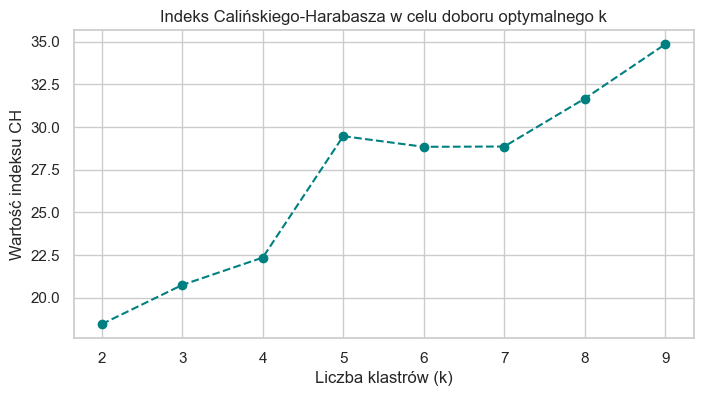

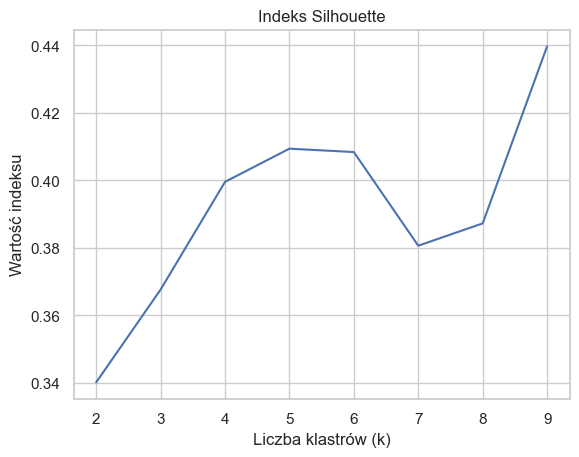

In [ ]:
# Indeks Calińskiego-Harabasza
ch_scores = []
k_range = range(2, 10)

for k in k_range:
    kmeans_eval = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_eval.fit_predict(X_std)
    ch_scores.append(calinski_harabasz_score(X_std, labels))

plt.figure(figsize=(8, 4))
plt.plot(k_range, ch_scores, marker='o', linestyle='--', color='teal')
plt.title('Indeks Calińskiego-Harabasza w celu doboru optymalnego k')
plt.xlabel('Liczba klastrów (k)')
plt.ylabel('Wartość indeksu CH')
plt.show()

sil_scores = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbls = km.fit_predict(X_std)
    sil_scores.append(silhouette_score(X_std, lbls))
    
plt.plot(list(range(2,10)), sil_scores)
plt.title("Indeks Silhouette")
plt.ylabel('Wartość indeksu')
plt.xlabel('Liczba klastrów (k)')

plt.show()

Na podstawie przeprowadzonej analizy taksonomicznej zdecydowaliśmy się na podział regionów NUTS 2 na cztery klastry. Wybór ten uznaliśmy za najlepszy kompromis między wynikami kryteriów statystycznych a możliwością uzyskania czytelnego podziału regionów. Przede wszystkim kierowaliśmy się wartością wskaźnika Silhouette, która wzrosła z 0,36 dla k = 3  do 0,400 dla k = 4. Jest to największy wzrost tego wskaźnika spośród analizowanych wariantów. Jednocześnie zwiększenie liczby klastrów do pięciu nie przynosi już równie wyraźnej poprawy. 

Wybór czterech klastrów znajduje również uzasadnienie w strukturze widocznej na dendrogramie, gdzie przy wysokości około 8.5  można zauważyć naturalny podział grup. Biorąc pod uwagę siedem zmiennych diagnostycznych, uznaliśmy, że taki podział pozwoli nam lepiej uchwycić zróżnicowanie regionów, a jednocześnie zachować przejrzystość wyników. Dzięki temu unikamy nadmiernego rozdrobnienia zbioru i tworzenia bardzo małych grup, które mogłyby być trudniejsze do interpretacji w kontekście atrakcyjności turystycznej.

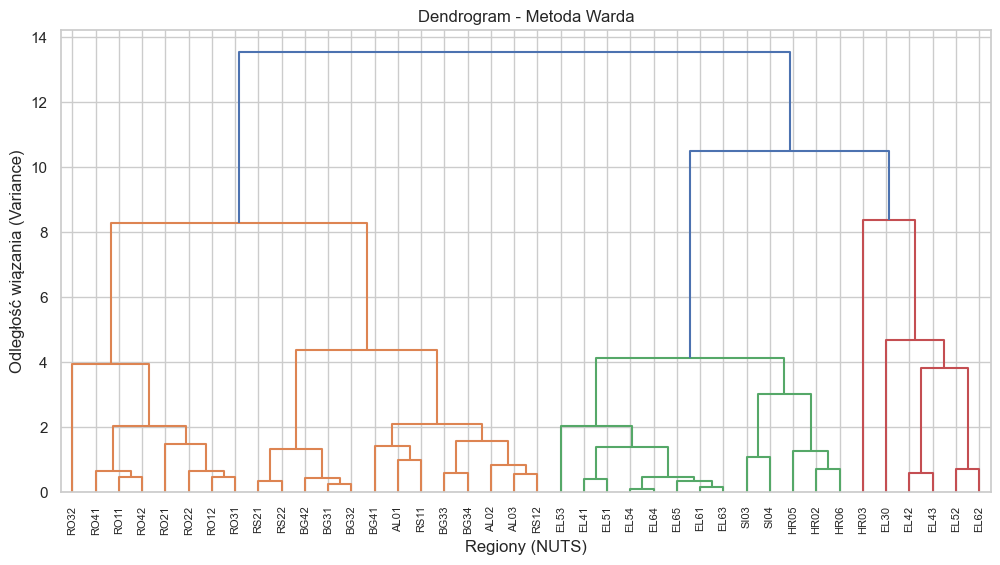

In [ ]:

# Ustalamy liczbę klastrów na podstawie wykresu Silhouette
k_clusters = 4

# Klastryzacja metodą Warda
Z_ward = linkage(X_std, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z_ward, labels=X_std.index, leaf_rotation=90)
plt.title('Dendrogram - Metoda Warda')
plt.xlabel('Regiony (NUTS)')
plt.ylabel('Odległość wiązania (Variance)')
plt.show()

# Przypisanie etykiet z metody Warda
df['Cluster_Ward'] = fcluster(Z_ward, k_clusters, criterion='maxclust')

# Metoda k-średnich
kmeans = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans.fit_predict(X_std) + 1 




## 3. Porządkowanie liniowe (Ranking)
Przeprowadzimy ocenę regionów tworząc syntetyczny miernik atrakcyjności:
1. **Metoda wzorcowa (Hellwiga)**: wykorzystuje odległość euklidesową od abstrakcyjnego punktu optymalnego ("wzorca rozwoju").
2. **Metoda bezwzorcowa**: klasyczna arytmetyczna agregacja zestawionych cech. Destymulanty zostały uprzednio przekształcone na stymulanty poprzez odwrócenie znaku.


In [70]:
# Metoda Hellwiga (Wzorcowa)
z_ideal_hellwig = X_std.max()

# Obliczenie odległości
d_hellwig = np.sqrt(((X_std - z_ideal_hellwig)**2).sum(axis=1))
d0 = d_hellwig.mean() + 2 * d_hellwig.std(ddof=1)
df['Hellwig_Score'] = 1 - (d_hellwig / d0)

# Metoda sum standaryzowanych (bezwzorcowa)
# Zmienne są ujednolicone, obliczamy średnią wartość po wierszach
df['Bezwzorcowa_Score'] = X_std.sum(axis=1) / len(wybrane_zmienne)

# Tworzenie rankingów
df['Rank_Hellwig'] = df['Hellwig_Score'].rank(ascending=False).astype(int)
df['Rank_Bezwzorcowa'] = df['Bezwzorcowa_Score'].rank(ascending=False).astype(int)

# Podgląd Top 10 regionów
ranking_cols = ['Hellwig_Score', 'Rank_Hellwig', 'Bezwzorcowa_Score', 'Rank_Bezwzorcowa']
print("\nTop 10 najbardziej atrakcyjnych turystycznie regionów Bałkanów (Wdg Metody Hellwiga):")
display(df[ranking_cols].sort_values('Rank_Hellwig').head(40))



Top 10 najbardziej atrakcyjnych turystycznie regionów Bałkanów (Wdg Metody Hellwiga):


,Hellwig_Score,Rank_Hellwig,Bezwzorcowa_Score,Rank_Bezwzorcowa
geo,,,,
HR03,0.534053,1,1.550416,1
EL42,0.356906,2,1.296792,2
EL30,0.350697,3,1.218748,3
EL43,0.338055,4,1.169300,4
EL62,0.273484,5,0.734553,5
EL52,0.266102,6,0.616182,6
RO32,0.255093,7,0.345869,7
SI04,0.193630,8,0.187885,9
RS11,0.183583,9,-0.040483,17


## 4. Podsumowanie i interpretacja wyników
Na koniec sprawdzimy zgodność zastosowanych metod porządkowania (współczynnik Spearmana) oraz przeanalizujemy profile powstałych klastrów.


Korelacja rang Spearmana między metodą wzorcową i bezwzorcową:


,Rank_Hellwig,Rank_Bezwzorcowa
Rank_Hellwig,1.000000,0.940525
Rank_Bezwzorcowa,0.940525,1.000000



Charakterystyka klastrów (Metoda Warda) w odniesieniu do wskaźników i rankingu:


,Hellwig_Score,Bezwzorcowa_Score,Noclegi_Ogolem,Liczba_Obiektow,Ruch_Lotniczy,Wskaznik_Zagranicznosci,Poziom_Cen_NUTS0,Wody_Doskonała_Jakość_NUTS0,Robbery
Cluster_Ward,,,,,,,,,
4,0.622,1.571,2.278408e+07,115285.000,8737.670,0.871,73.300,894.000,1238.000
3,0.334,0.816,1.979694e+07,4128.400,15050.354,0.871,83.000,1728.000,988.200
2,0.165,-0.084,2.230184e+06,2094.692,766.015,0.559,81.992,1272.923,432.692
1,0.159,-0.217,3.027556e+06,2169.333,2423.083,0.383,58.805,72.143,4741.714


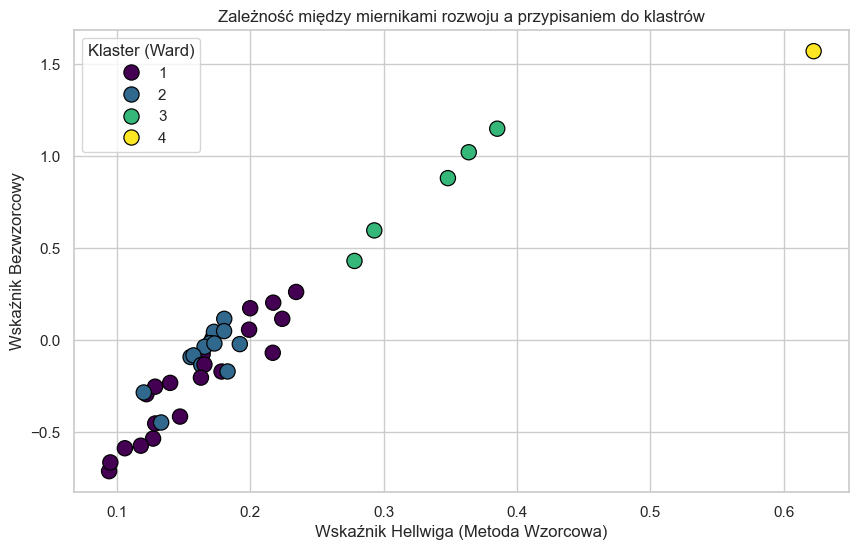

In [48]:
# Korelacja wyników z metod porządkowania
korelacja_rankingow = df[['Rank_Hellwig', 'Rank_Bezwzorcowa']].corr(method='spearman')
print("Korelacja rang Spearmana między metodą wzorcową i bezwzorcową:")
display(korelacja_rankingow)

# Profilowanie klastrów
agg_dict = {
    'Hellwig_Score': 'mean',
    'Bezwzorcowa_Score': 'mean',
    'Noclegi_Ogolem': 'mean',
    'Liczba_Obiektow': 'mean',
    'Ruch_Lotniczy': 'mean',
    'Wskaznik_Zagranicznosci': 'mean',
    'Poziom_Cen_NUTS0': 'mean',
    'Wody_Doskonała_Jakość_NUTS0': 'mean',
    'Robbery': 'mean'
}

# Zabezpieczenie na wypadek brakujących kolumn
agg_dict = {k: v for k, v in agg_dict.items() if k in df.columns}

cluster_summary = df.groupby('Cluster_Ward').agg(agg_dict).round(3)

print("\nCharakterystyka klastrów (Metoda Warda) w odniesieniu do wskaźników i rankingu:")
display(cluster_summary.sort_values(by='Hellwig_Score', ascending=False))

# Wykres rozrzutu dla obu metod z kolorowaniem po klastrach
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Hellwig_Score', 
    y='Bezwzorcowa_Score', 
    hue='Cluster_Ward', 
    palette='viridis', 
    data=df, 
    s=120, 
    edgecolor='black'
)
plt.title('Zależność między miernikami rozwoju a przypisaniem do klastrów')
plt.xlabel('Wskaźnik Hellwiga (Metoda Wzorcowa)')
plt.ylabel('Wskaźnik Bezwzorcowy')
plt.legend(title='Klaster (Ward)')
plt.show()


Analiza korelacji miar syntetycznych z oryginalnymi zmiennymi diagnostycznymi

In [ ]:
# Korelacja miar porządkowania ze zmiennymi
korelacja_cechy = df[['Hellwig_Score', 'Bezwzorcowa_Score']].join(X_std).corr().loc[['Hellwig_Score', 'Bezwzorcowa_Score'], wybrane_zmienne]
print("\nKorelacja miar syntetycznych z oryginalnymi zmiennymi diagnostycznymi:")
display(korelacja_cechy.round(3))

# Klasyfikacja typologiczna dla Metody bezwzorcowej
mean_b = df['Bezwzorcowa_Score'].mean()
std_b = df['Bezwzorcowa_Score'].std(ddof=1)

warunki_b = [
    (df['Bezwzorcowa_Score'] >= mean_b + std_b),
    (df['Bezwzorcowa_Score'] >= mean_b) & (df['Bezwzorcowa_Score'] < mean_b + std_b),
    (df['Bezwzorcowa_Score'] >= mean_b - std_b) & (df['Bezwzorcowa_Score'] < mean_b),
    (df['Bezwzorcowa_Score'] < mean_b - std_b)
]


Korelacja miar syntetycznych z oryginalnymi zmiennymi diagnostycznymi:


,Noclegi_Ogolem,Liczba_Obiektow,Ruch_Lotniczy,Wody_Doskonała_Jakość_NUTS0,Wskaznik_Zagranicznosci,Poziom_Cen_NUTS0,Robbery
Hellwig_Score,0.814,0.735,0.641,0.358,0.673,0.309,-0.292
Bezwzorcowa_Score,0.815,0.541,0.651,0.510,0.786,0.414,-0.479


Zastosowane techniki porządkowania liniowego oraz analizy skupień spójnie zidentyfikowały turystyczne bieguny rozwoju na Bałkanach. Regiony sklasyfikowane w najwyższych grupach potencjału (Klaster 4 oraz klasa "Bardzo wysoki") odznaczają się nie tylko rozwiniętą bazą obiektów i dostępnością lotniczą, ale też wybitną zdolnością przyciągania gości zagranicznych. Przeprowadzona wielowymiarowa ewaluacja tworzy stabilny i obiektywny obraz przestrzeni, który z powodzeniem może stanowić fundament do podejmowania strategicznych decyzji inwestycyjnych lub samorządowych w badanym regionie.

## Mapa regionów wg. porządkowania Hellwiga i metody bezwzorcowej


Podział regionów na klasy atrakcyjności turystycznej:


,Hellwig_Score,Klasa_Hellwig
geo,,
HR03,0.534053,1_Bardzo wysoki
EL42,0.356906,1_Bardzo wysoki
EL30,0.350697,1_Bardzo wysoki
EL43,0.338055,1_Bardzo wysoki
EL62,0.273484,1_Bardzo wysoki
EL52,0.266102,1_Bardzo wysoki
RO32,0.255093,2_Wysoki
SI04,0.193630,2_Wysoki
RS11,0.183583,2_Wysoki


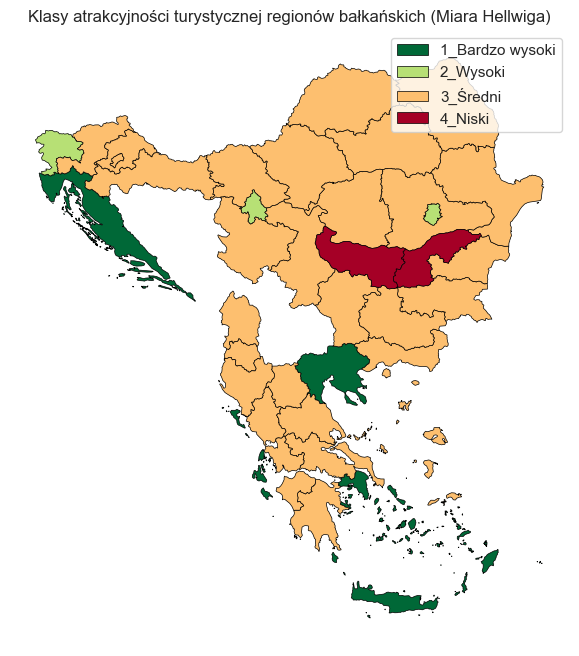

In [71]:
# Klasyfikacja typologiczna dla Metody Hellwiga
mean_h = df['Hellwig_Score'].mean()
std_h = df['Hellwig_Score'].std(ddof=1)

warunki = [
    (df['Hellwig_Score'] >= mean_h + std_h),
    (df['Hellwig_Score'] >= mean_h) & (df['Hellwig_Score'] < mean_h + std_h),
    (df['Hellwig_Score'] >= mean_h - std_h) & (df['Hellwig_Score'] < mean_h),
    (df['Hellwig_Score'] < mean_h - std_h)
]
klasy = ['1_Bardzo wysoki', '2_Wysoki', '3_Średni', '4_Niski']
df['Klasa_Hellwig'] = np.select(warunki, klasy, default='Brak')

print("\nPodział regionów na klasy atrakcyjności turystycznej:")
display(df[['Hellwig_Score', 'Klasa_Hellwig']].sort_values('Hellwig_Score', ascending=False))

# Wizualizacja przestrzenna rankingu
nuts2_map = gpd.read_file("https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_03M_2021_4326_LEVL_2.geojson")
map_df = nuts2_map.merge(df, left_on='NUTS_ID', right_index=True)

# Generowanie mapy
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
map_df.plot(column='Klasa_Hellwig',
            cmap='RdYlGn_r', # Zielony dla najlepszych, czerwony dla najsłabszych
            edgecolor='black',
            linewidth=0.5,
            legend=True,
            ax=ax)

plt.title('Klasy atrakcyjności turystycznej regionów bałkańskich (Miara Hellwiga)')
ax.set_axis_off()
plt.show()

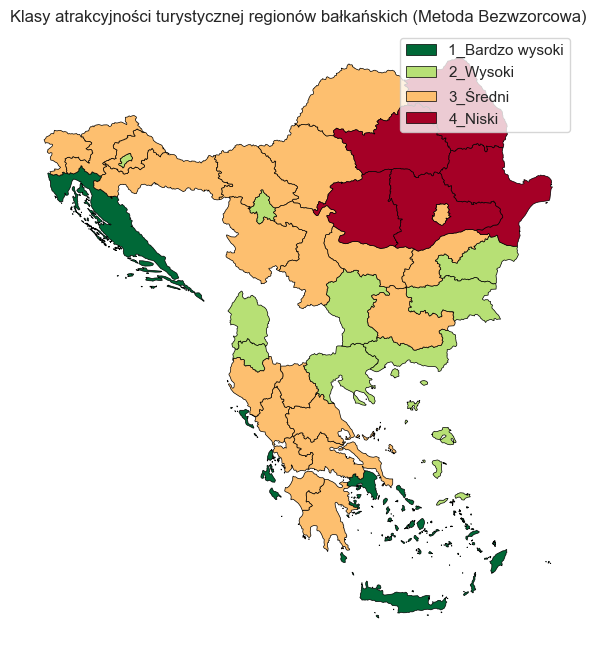

In [72]:
df['Klasa_Bezwzorcowa'] = np.select(warunki_b, klasy, default='Brak')

# Wizualizacja przestrzenna rankingu (Metoda Bezwzorcowa)
map_df_b = nuts2_map.merge(df, left_on='NUTS_ID', right_index=True)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
map_df_b.plot(column='Klasa_Bezwzorcowa',
            cmap='RdYlGn_r', # ta sama kolorystyka
            edgecolor='black',
            linewidth=0.5,
            legend=True,
            ax=ax)

plt.title('Klasy atrakcyjności turystycznej regionów bałkańskich (Metoda Bezwzorcowa)')
ax.set_axis_off()
plt.show()

## Podsumowanie oceny porządkowania liniowego

Współczynnik korelacji rang Spearmana między metodą wzorcową (Hellwiga) a bezwzorcową osiągnął wartość 0,94. Tak silna korelacja dodatnia dowodzi, że ostateczny ranking jest wysoce stabilny i niemal całkowicie niezależny od wybranej techniki agregacji danych. Model jest odporny na zniekształcenia statystyczne.   
Weryfikacja empiryczna rankingu: Skonstruowany wskaźnik syntetyczny w pełni odzwierciedla rzeczywisty rozkład potencjału turystycznego na Bałkanach. Czołowe pozycje w rankingu (m.in. chorwacka Jadranska Hrvatska - HR03, greckie Wyspy Egejskie - EL42) zajmują regiony przybrzeżne o wysoce rozwiniętej infrastrukturze. Dominują one w statystykach liczby obiektów turystycznych oraz wykazują silny wskaźnik zagraniczności noclegów, co potwierdza merytoryczną poprawność doboru zmiennych diagnostycznych.   
Zobiektywizowana kategoryzacja: Podział regionów na cztery klasy typologiczne, dokonany w oparciu o średnią arytmetyczną i odchylenie standardowe miary Hellwiga, zdejmuje z analizy ciężar arbitralnych decyzji badacza. Powstałe klasy potencjału (od bardzo wysokiego po niski) korelują wprost z wynikami analizy skupień (algorytm Warda). Liderzy rankingu posiadający najwyższy wskaźnik Hellwiga naturalnie formują odseparowany Klaster 4, charakteryzujący się bezwzględną dominacją w liczbie udzielonych noclegów ogółem. 

## Charakterystyka podziału na klastry

Naszą ocenę podziału na  klastry, zacznijmy od porównania w jaki sposób obie metody zgrupowały nasze obszary. W tym celu nałożymy otrzymane grupy na mape. Pozwoli nam to przedewszystkim zobaczyć czy obie metody widzą podobne zależności w danych.

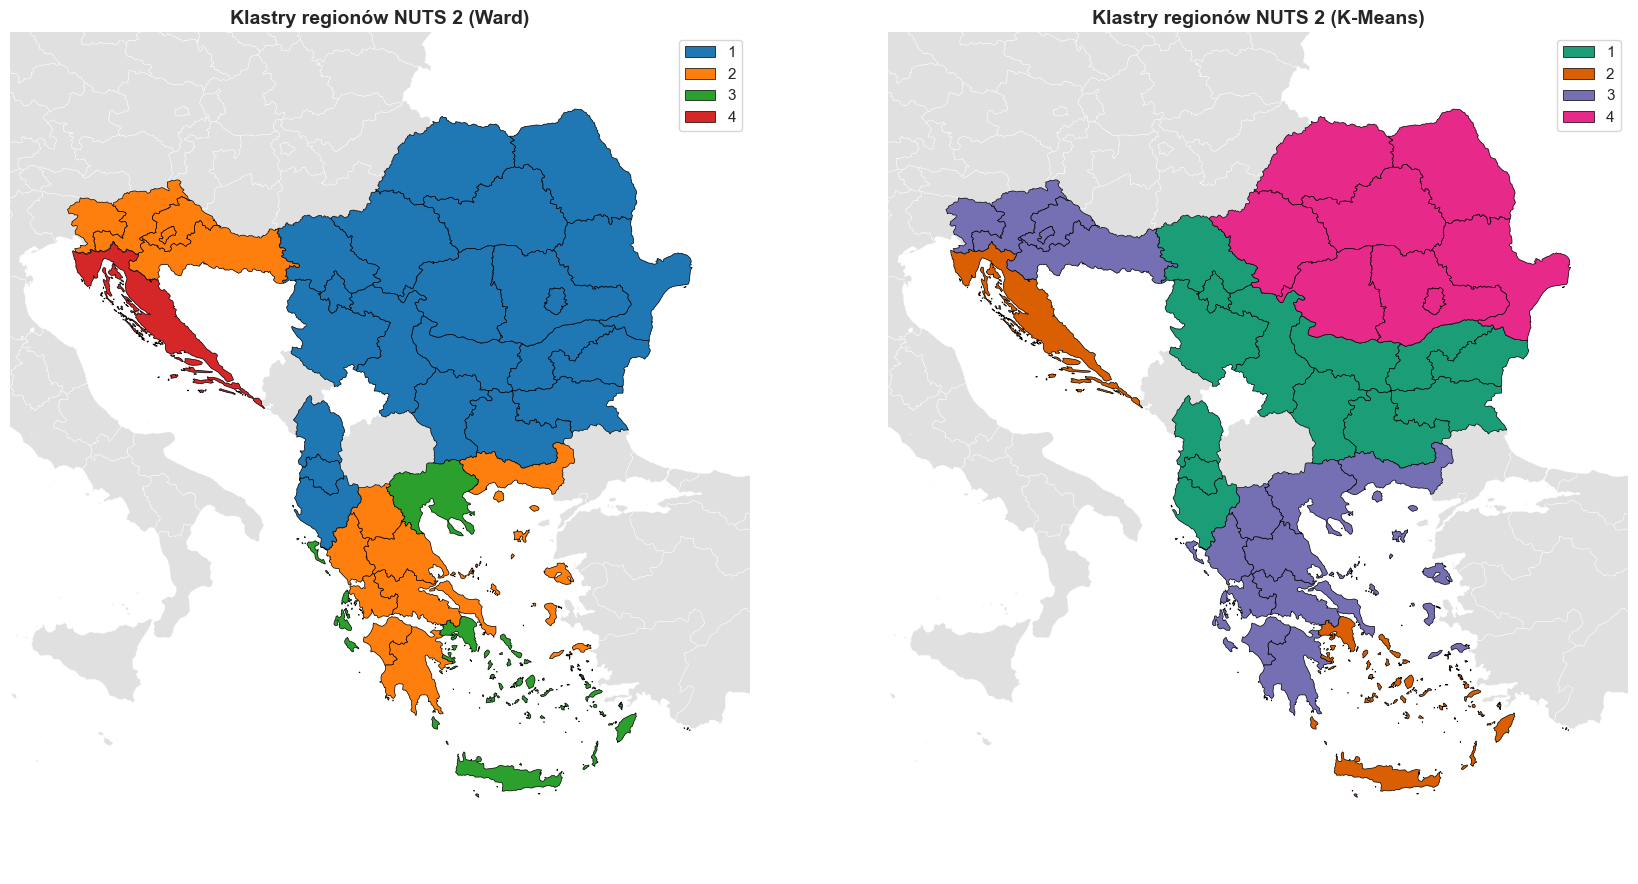

In [ ]:
# Pobranie granic NUTS 2 dla całej Europy
nuts2_map = gpd.read_file("https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_03M_2021_4326_LEVL_2.geojson")

# Połączenie z danymi klastrów
merged_map = nuts2_map.merge(df, left_on='NUTS_ID', right_on='geo', how='inner')

# Rzutowanie klastrów na stringi, aby Matplotlib traktował je jako niezależne kategorie, a nie liczby ciągłe
merged_map['Cluster_Ward_str'] = merged_map['Cluster_Ward'].astype(str)
merged_map['Cluster_KMeans_str'] = merged_map['Cluster_KMeans'].astype(str)

# Tworzenie okna
fig, ax = plt.subplots(1, 2, figsize=(18, 9))

# Ustalenie granic kadru wokół Bałkanów (+ bufor 1.5 stopnia z każdej strony)
minx, miny, maxx, maxy = merged_map.total_bounds
margin = 1.5

# Kolory dla otoczenia
KOLOR_MORZA = "#92ccf9"      
KOLOR_SASIADOW = '#e0e0e0'   

for a in ax:
    # Ustawienie morza jako tła wykresu
    a.set_facecolor(KOLOR_MORZA)
    
    # Warstwa 1: Wszystkie regiony Europy (tło z sąsiadami)
    nuts2_map.plot(
        ax=a, 
        color=KOLOR_SASIADOW, 
        edgecolor='white', 
        linewidth=0.3
    )

# Warstwa 2 LEWA: Klastry Ward
merged_map.plot(
    column='Cluster_Ward_str',
    categorical=True,
    legend=True,
    cmap='tab10',
    edgecolor='black',
    linewidth=0.5,
    ax=ax[0]
)
ax[0].set_title('Klastry regionów NUTS 2 (Ward)', fontsize=14, fontweight='bold')

# Warstwa 2 PRAWA: Klastry K-Means
merged_map.plot(
    column='Cluster_KMeans_str',
    categorical=True,
    legend=True,
    cmap='Dark2',  
    edgecolor='black',
    linewidth=0.5,
    ax=ax[1]
)
ax[1].set_title('Klastry regionów NUTS 2 (K-Means)', fontsize=14, fontweight='bold')

# Kadrowanie widoku do obszaru Bałkanów
for a in ax:
    a.set_xlim(minx - margin, maxx + margin)
    a.set_ylim(miny - margin, maxy + margin)
    a.axis('off')  # Ukrycie ramki i osi ze współrzędnymi

plt.tight_layout()
plt.show()

Jak obserwujemy podział terytorium w przypadku obu metod jest zbliżony, jednak nie jest identyczny. Sprawdzmy za pomocą skorygowanego indeksu randa stopień w jakim pokrywają się nasze klatry dla obu metod.następnie zajmijmy się głebszą analizą powstałych klastrów.

In [41]:
adjusted_rand_score(df['Cluster_KMeans'] , df['Cluster_Ward'])

0.6019356165188274

Aby stwierdzić jakimi cechami charakteryzują się poszczególne klastry, zczniemy od badania rozkładów cech miedzy obszarami, by sprawdzić czy któraś z nich nie jest stała dla wszystkich obserwacji. W tym celu przeprowadzimy nieparametryczny test kruskalla-wallisa dla klastrów 1 - 4

In [42]:

zmienne = [
    'Noclegi_Ogolem', 'Liczba_Obiektow', 'Ruch_Lotniczy', 
    'Poziom_Cen_NUTS0', 'Wody_Doskonała_Jakość_NUTS0', 
    'Robbery', 'Wskaznik_Zagranicznosci', 
    
]

print("--- Wyniki testu Kruskala-Wallisa  ---")

for zmienna in zmienne:
    
    
    
    grupy = [group[zmienna].values for _ , group in df.groupby('Cluster_Ward')]
       
    h_stat, p_val = stats.kruskal(*grupy)
    istotna = "*" if p_val < 0.05 else ""
    print(f"Zmienna: {zmienna:30s} | H: {h_stat:8.3f} | p-value: {round(p_val, 4)} {istotna}")
        

--- Wyniki testu Kruskala-Wallisa  ---
Zmienna: Noclegi_Ogolem                 | H:   15.432 | p-value: 0.0015 *
Zmienna: Liczba_Obiektow                | H:    8.396 | p-value: 0.0385 *
Zmienna: Ruch_Lotniczy                  | H:   12.919 | p-value: 0.0048 *
Zmienna: Poziom_Cen_NUTS0               | H:   31.130 | p-value: 0.0 *
Zmienna: Wody_Doskonała_Jakość_NUTS0    | H:   20.539 | p-value: 0.0001 *
Zmienna: Robbery                        | H:   18.634 | p-value: 0.0003 *
Zmienna: Wskaznik_Zagranicznosci        | H:   13.095 | p-value: 0.0044 *


Jak widać po przeprowadzonym teście, którego hipotezą zerową jest równość rozkładów zmiennych w poszczegółnych klastrach, wyniki dla każdej z cech każą nam odrzucić hipoteze zerową, zatem uznajemy róznice pomiedzy wartościami zmienynch w klastrach za istotne. 

Następnym krokiem w naszym badaniu, jest określenie cech otrzymanych klastrów. Aby porównać wartości poszczególnych zniennych posłużymy się średnią.

# Kmeans


In [43]:
dane_klaster_srednie = df.groupby('Cluster_KMeans').mean(numeric_only=True)

display(dane_klaster_srednie.transpose())



Cluster_KMeans,1,2,3,4
Noclegi_Ogolem,2.938146e+06,2.394453e+07,3.665538e+06,3.172846e+06
Liczba_Obiektow,2.564077e+03,3.178250e+04,2.401867e+03,1.527875e+03
Ruch_Lotniczy,1.959898e+03,1.729972e+04,1.649917e+03,3.175757e+03
Poziom_Cen_NUTS0,5.966923e+01,8.057500e+01,8.212667e+01,5.740000e+01
Wody_Doskonała_Jakość_NUTS0,8.638462e+01,1.519500e+03,1.333600e+03,4.900000e+01
Robbery,1.028308e+03,1.268250e+03,4.487333e+02,1.077600e+04
Wskaznik_Zagranicznosci,5.143306e-01,8.808141e-01,5.980243e-01,1.703508e-01
Cluster_Ward,1.000000e+00,3.250000e+00,2.133333e+00,1.000000e+00
Hellwig_Score,1.775817e-01,4.298827e-01,1.811968e-01,1.291711e-01
Bezwzorcowa_Score,-4.174082e-02,1.155697e+00,-4.534820e-03,-5.015166e-01


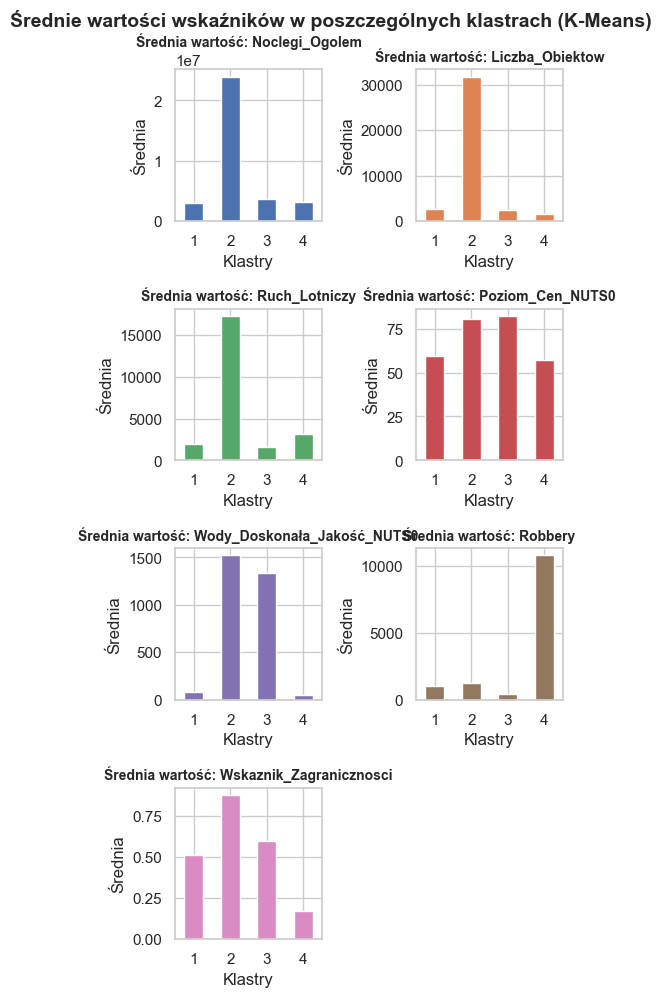

In [44]:
numeric_log = ['Noclegi_Ogolem','Liczba_Obiektow','Ruch_Lotniczy','Poziom_Cen_NUTS0','Wody_Doskonała_Jakość_NUTS0', 'Robbery','Wskaznik_Zagranicznosci' ]


plt.figure(figsize=(5, 17))

for i, col in enumerate(numeric_log):
    
    plt.subplot(len(numeric_log), 2, i + 1)
    
    dane_klaster_srednie[col].plot(kind='bar', ax=plt.gca(), color=f'C{i}', width=0.52)
    
    plt.title(f'Średnia wartość: {col}', fontsize=10, fontweight='bold')
    plt.xlabel('Klastry')
    plt.ylabel('Średnia')
    plt.xticks(rotation=0)

plt.suptitle('Średnie wartości wskaźników w poszczególnych klastrach (K-Means)', fontsize=14, fontweight='bold')
plt.tight_layout()  
plt.show()


Jak możemy zaobserwować nasze klastry dzielą się na 4 grupy o szczególnych specyfikacjach:

Klaster 1 – Regiony o umiarkowanym potencjale turystycznym:
Charakteryzuje się średnim udziałem turystów zagranicznych (wskaźnik ok. 0,5), niewielką liczbą doskonałej jakości kąpielisk, niskim natężeniem ruchu noclegowego oraz umiarkowanym poziomem cen i przestępczości. Są to obszary wykorzystywane turystycznie w sposób umiarkowany, bez wyraźnego profilu masowego.

Klaster 2 – Liderzy turystyki masowej (Szczytowy potencjał):
Zdecydowanie dominująca grupa regionów, charakteryzująca się najwyższym wskaźnikiem turystyki zagranicznej (blisko 0,9), największą liczbą obiektów noclegowych, rekordową liczbą udzielonych noclegów oraz najwyższym ruchem lotniczym. Obszary te dysponują również najbogatszą infrastrukturą czystych kąpielisk przy zachowaniu stosunkowo niskiego poziomu przestępczości i wysokiego poziomu cen.

Klaster 3 – Spokojne regiony przybrzeżne premium:
Obszar o wyspecjalizowanym profilu – charakteryzuje się bardzo dużą liczbą kąpielisk o doskonałej jakości wód oraz najniższym poziomem przestępczości ze wszystkich grup. Jednocześnie notuje wysoki poziom cen przy znacznie mniejszej skali masowego ruchu turystycznego (niski ruch lotniczy, umiarkowana liczba obiektów i noclegów). Wskazuje to na regiony o charakterze wypoczynkowym, mniej dostępnym komunikacyjnie, zorientowane na turystykę lokalną lub kameralną turystykę premium.

Klaster 4 – Regiony nieturystyczne / problematyczne:
Grupa o najniższym potencjale turystycznym, wyróżniająca się ekstremalnie wysokim poziomem przestępczości (ponad 10 tys. rozbojów) przy najniższym wskaźniku turystyki zagranicznej (poniżej 0,2). Obszary te cechują się brakiem atrakcyjnej bazy kąpieliskowej, słabo rozwiniętą bazą noclegową oraz najniższym poziomem cen, co wskazuje na ich wybitnie przemysłowy, zurbanizowany lub wewnętrzny charakter.



# Ward

Spójrzmy teraz na charakterystykę grup powstałych metodą Warda

In [49]:
dane_klaster_srednie_ward = df.groupby('Cluster_Ward').agg(agg_dict).round(3)
display(dane_klaster_srednie_ward.transpose())

Cluster_Ward,1,2,3,4
Hellwig_Score,0.159,0.165,3.340000e-01,6.220000e-01
Bezwzorcowa_Score,-0.217,-0.084,8.160000e-01,1.571000e+00
Noclegi_Ogolem,3027555.619,2230184.308,1.979694e+07,2.278408e+07
Liczba_Obiektow,2169.333,2094.692,4.128400e+03,1.152850e+05
Ruch_Lotniczy,2423.083,766.015,1.505035e+04,8.737670e+03
Wskaznik_Zagranicznosci,0.383,0.559,8.710000e-01,8.710000e-01
Poziom_Cen_NUTS0,58.805,81.992,8.300000e+01,7.330000e+01
Wody_Doskonała_Jakość_NUTS0,72.143,1272.923,1.728000e+03,8.940000e+02
Robbery,4741.714,432.692,9.882000e+02,1.238000e+03


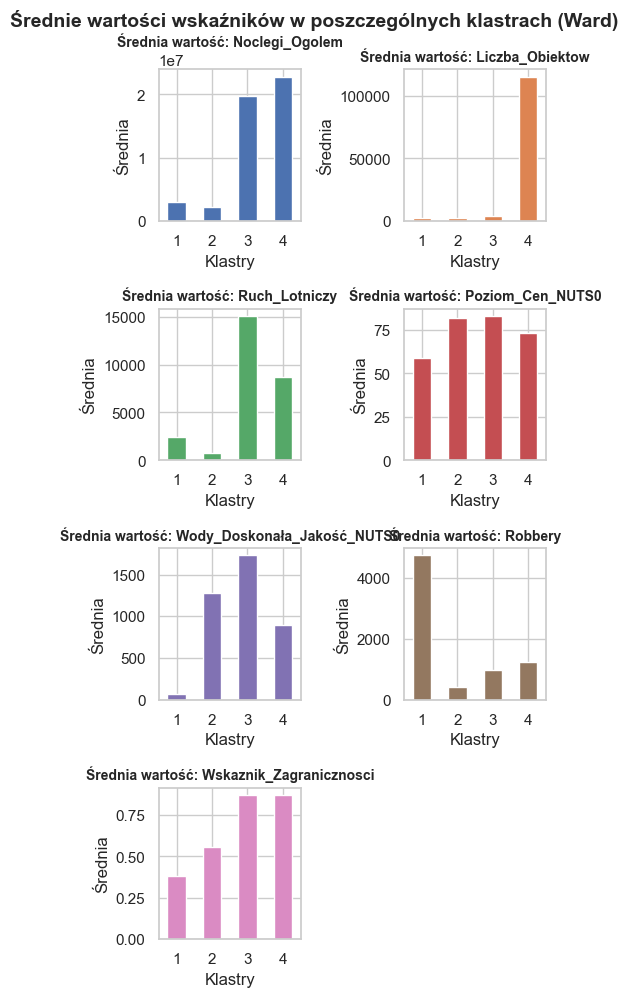

In [50]:
numeric_log = ['Noclegi_Ogolem','Liczba_Obiektow','Ruch_Lotniczy','Poziom_Cen_NUTS0','Wody_Doskonała_Jakość_NUTS0', 'Robbery','Wskaznik_Zagranicznosci' ]


plt.figure(figsize=(5, 17))

for i, col in enumerate(numeric_log):
   
    plt.subplot(len(numeric_log), 2, i + 1)
    
    dane_klaster_srednie_ward[col].plot(kind='bar', ax=plt.gca(), color=f'C{i}', width=0.52)
    
    plt.title(f'Średnia wartość: {col}', fontsize=10, fontweight='bold')
    plt.xlabel('Klastry')
    plt.ylabel('Średnia')
    plt.xticks(rotation=0)

plt.suptitle('Średnie wartości wskaźników w poszczególnych klastrach (Ward)', fontsize=14, fontweight='bold')
plt.tight_layout()  
plt.show()

Jak możemy zaobserwować nasze klastry dzielą się na 4 grupy o szczególnych specyfikacjach:

Klaster 1:
Są to obszary o najniższym potencjale turystycznym, które charakteryzują się najwyższym poziomem przestępczości, najniższym wskaźnikiem turystyki zagranicznej, najniższym poziomem cen oraz bardzo małą ilością czystych kąpielisk i obiektów noclegowych. Ruch turystyczny opiera się tu głównie na mieszkańcach lokalnych, a same regiony mają charakter wybitnie przemysłowy lub wewnętrzny.

Klaster 2:
To obszary spokojniejsze i maksymalnie bezpieczne – charakteryzują się najniższą przestępczością ze wszystkich grup oraz dużą ilością kąpielisk o doskonałej jakości wód. Posiadają jednak drastycznie niższy ruch lotniczy, małą liczbę obiektów i niską ogólną liczbę noclegów. Przy bardzo wysokim poziomie cen są to najpewniej kameralne, drogie regiony wypoczynkowe, wolne od masowej infrastruktury hotelowej i lotniczej.

Klaster 3:
To obszar o bardzo wysokim potencjale i profilu turystyki masowej. Charakteryzuje się najwyższym ruchem lotniczym, największą ilością czystych kąpielisk, bardzo wysokim wskaźnikiem turystyki zagranicznej, najwyższymi cenami oraz bardzo dużą liczbą noclegów przy zachowaniu niskiej przestępczości. Są to główne, doskonale skomunikowane lotniczo destynacje wakacyjne.

Klaster 4:
Jest to wyizolowany mikro-klaster stanowiący absolutnego lidera zestawienia. Charakteryzuje się gigantyczną, wręcz ekstremalną liczbą obiektów noclegowych (ponad 110 tysięcy), najwyższą łączną liczbą udzielonych noclegów oraz bardzo wysokim wskaźnikiem turystyki zagranicznej. Metoda Warda odcięła ten region (Jadranska Hrvatska) jako odrębną wartość skrajnie odstającą, która swoją skalą bazy noclegowej całkowicie dominuje nad resztą analizowanych obszarów.

Spróbujmy teraz porównać ze sobą obie wykorzystane metody. 

In [51]:
# Porównanie wyników grupowania
print("\nMacierz pomyłek obu metod grupowania:")
display(pd.crosstab(df['Cluster_Ward'], df['Cluster_KMeans'], 
                    rownames=['Ward'], colnames=['K-Means']))


Macierz pomyłek obu metod grupowania:


K-Means,1,2,3,4
Ward,,,,
1,13,0,0,8
2,0,0,13,0
3,0,3,2,0
4,0,1,0,0


Porównanie wyników klasyfikacji 

Analiza macierzy krzyżowej potwiedza wysoką spójność obu metod w odniesieniu do kluczowych segmentów rynkowych przy jednoczesnym ujawnieniu specyfiki decyzyjnej poszczególnych algorytmów:

Idealna zgodność segmentu kameralnego/premium: Obie metody zidentyfikowały tę samą grupę 13 regionów (Klaster 2 Warda vs Klaster 3 K-Means), cechującą się maksymalnym bezpieczeństwem i wysoka jakością środowiska naturalnego.

Większa szczegółowość K-Means w strefie niskiego potencjału: Algorytm K-Means podzielił szeroki Klaster 1 Warda na dwie podgrupy, odseparowując obszary o charakterze wybitnie problematycznym i wysokim wskaźniku przestępczości (8 regionów w K-Means 4) od regionów ze średnim potencjałem krajowym (13 regionów w K-Means 1).

Różnica w traktowaniu wartości skrajnych: Metoda Warda stworzyła jednoelementowy mikro-klaster (Ward 4) dla absolutnego lidera bazy noclegowej, podczas gdy K-Means włączył ten region do 4-elementowej grupy głównych liderów turystycznych (K-Means 2).

# Wykresy radarowe dla metod klastryzacji

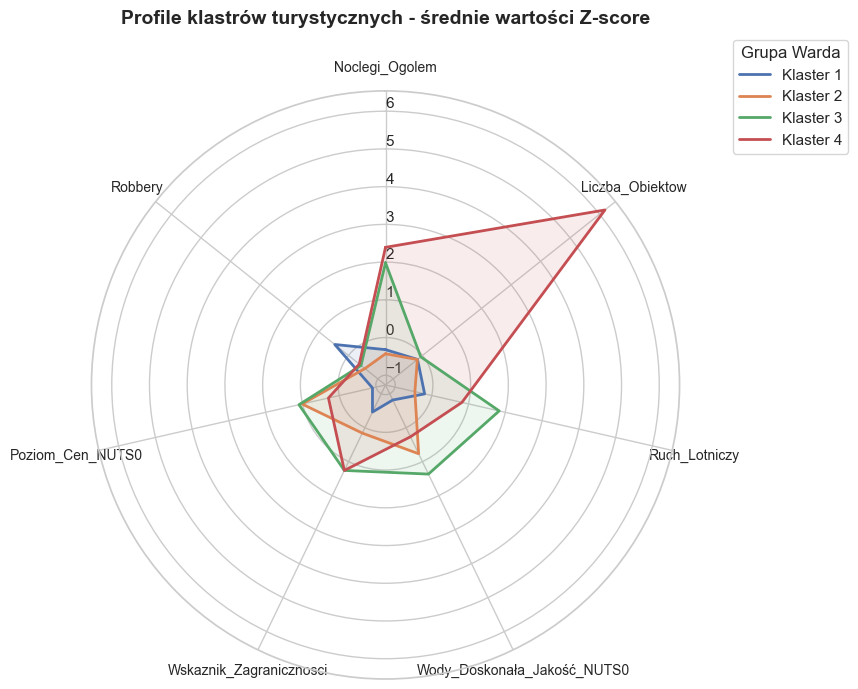

In [ ]:
# Przygotowanie danych (wyciągnięcie średnich Z-score dla klastrów)
X_std_radar = X_std.copy()
X_std_radar['Cluster_Ward'] = df['Cluster_Ward']
dane_radar = X_std_radar.groupby('Cluster_Ward')[wybrane_zmienne].mean()

# Definicja osi (kątów) dla wykresu wielokątnego
kategorie = list(dane_radar.columns)
N = len(kategorie)
katy = [n / float(N) * 2 * pi for n in range(N)]
katy += katy[:1] # Zamknięcie pętli

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

# Ustawienie przesunięcia pierwszej osi na górę (godzina 12:00)
ax.set_theta_offset(pi / 2)
ax.set_theta_direction(-1)

# Nanoszenie profili klastrów na wykres
for idx, row in dane_radar.iterrows():
    wartosci = row.values.flatten().tolist()
    wartosci += wartosci[:1] 
    
    ax.plot(katy, wartosci, linewidth=2, linestyle='solid', label=f'Klaster {idx}')
    ax.fill(katy, wartosci, alpha=0.1)

# Formatowanie wyglądu
plt.xticks(katy[:-1], kategorie, size=10)
ax.set_rlabel_position(0)
plt.title('Profile klastrów turystycznych - średnie wartości Z-score', size=14, y=1.1, fontweight='bold')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), title="Grupa Warda")

plt.tight_layout()
plt.show()

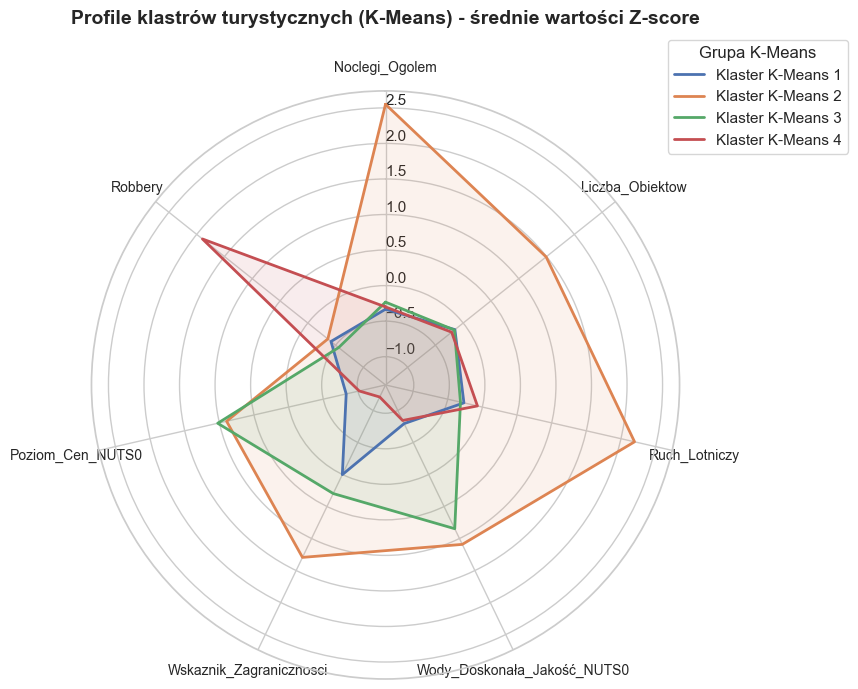

In [69]:
# Przygotowanie danych (wyciągnięcie średnich Z-score dla klastrów K-Means)
X_std_radar_km = X_std.copy()

X_std_radar_km['Cluster_KMeans'] = df['Cluster_KMeans']
dane_radar_km = X_std_radar_km.groupby('Cluster_KMeans')[wybrane_zmienne].mean()

# Definicja osi (kątów) dla wykresu wielokątnego
kategorie = list(dane_radar_km.columns)
N = len(kategorie)
katy = [n / float(N) * 2 * pi for n in range(N)]
katy += katy[:1] # Zamknięcie pętli

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

# Ustawienie przesunięcia pierwszej osi na górę (godzina 12:00)
ax.set_theta_offset(pi / 2)
ax.set_theta_direction(-1)

# Nanoszenie profili klastrów K-Means na wykres
for idx, row in dane_radar_km.iterrows():
    wartosci = row.values.flatten().tolist()
    wartosci += wartosci[:1] 
    
    ax.plot(katy, wartosci, linewidth=2, linestyle='solid', label=f'Klaster K-Means {idx}')
    ax.fill(katy, wartosci, alpha=0.1)

# Formatowanie wyglądu
plt.xticks(katy[:-1], kategorie, size=10)
ax.set_rlabel_position(0)
plt.title('Profile klastrów turystycznych (K-Means) - średnie wartości Z-score', size=14, y=1.1, fontweight='bold')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), title="Grupa K-Means")

plt.tight_layout()
plt.show()